In [1]:
!pip install statsmodels

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import Markdown, display
from openbb import obb
from statsmodels import regression

In [3]:
obb.user.preferences.output_type = "dataframe"

In [4]:
symbols = ["RELIANCE.NS", "HINDALCO.NS" , "SBIN.NS", "TCS.NS", "TRENT.NS", "EICHERMOT.NS", "DRREDDY.NS", "ITC.NS", "NIFTYBEES.NS"]

data = obb.equity.price.historical(
    symbols,
    start_date="2023-01-01",
    end_date="2025-12-31",
    provider="yfinance",
).pivot(columns="symbol", values="close")

## Returns (aligned on a common date index)
Equal-weight portfolio = **mean** of the 8 stock returns (summing would create an 8x levered portfolio).

In [5]:
rets = data.pct_change(fill_method=None).dropna()
benchmark_returns = rets.pop("NIFTYBEES.NS")
benchmark_returns.name = "NIFTYBEES"

In [6]:
portfolio_returns = rets.mean(axis=1)
portfolio_returns.name = "portfolio"
assert portfolio_returns.index.equals(benchmark_returns.index)

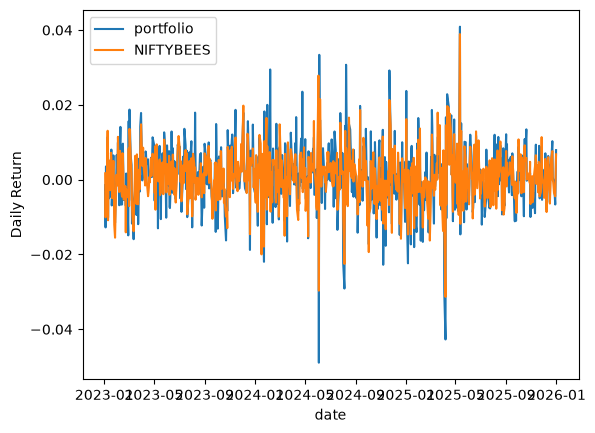

In [7]:
portfolio_returns.plot()
benchmark_returns.plot()
plt.ylabel("Daily Return")
plt.legend()
plt.show()

## Alpha / beta: OLS of portfolio (y) on NIFTYBEES (x)

In [8]:
def linreg(x, y):
    x = sm.add_constant(x)
    model = regression.linear_model.OLS(y, x).fit()
    return model.params[0], model.params[1]

In [9]:
X = benchmark_returns.values
Y = portfolio_returns.values
alpha, beta = linreg(X, Y)
print(f"Alpha (daily): {alpha:.6f}")
print(f"Beta: {beta:.4f}")

Alpha (daily): 0.000186
Beta: 1.0455


In [10]:
model = sm.OLS(Y, sm.add_constant(X)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.683
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     1584.
Date:                Fri, 16 Oct 2026   Prob (F-statistic):          1.38e-185
Time:                        11:50:45   Log-Likelihood:                 2885.4
No. Observations:                 737   AIC:                            -5767.
Df Residuals:                     735   BIC:                            -5758.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.000      1.041      0.2

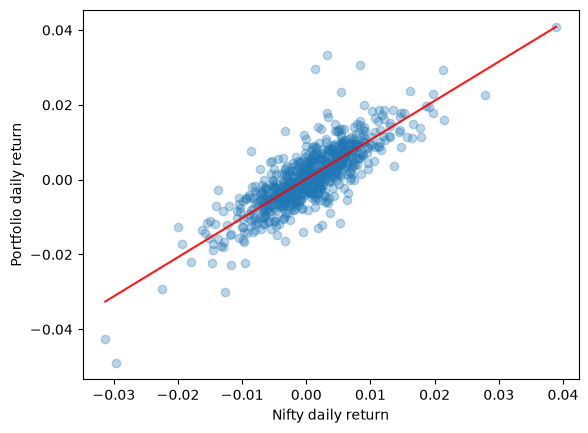

In [11]:
X2 = np.linspace(X.min(), X.max(), 100)
Y_hat = X2 * beta + alpha

plt.scatter(X, Y, alpha=0.3)
plt.xlabel("Nifty daily return")
plt.ylabel("Portfolio daily return")
plt.plot(X2, Y_hat, "r", alpha=0.9)
plt.show()

## Beta-hedged portfolio
Long the portfolio, short `beta` units of NIFTYBEES. The hedged return should have ~zero beta to the benchmark.

In [12]:
hedged_portfolio_returns = portfolio_returns - beta * benchmark_returns
hedged_portfolio_returns.name = "hedged"

In [13]:
alpha_h, beta_h = linreg(X, hedged_portfolio_returns.values)
print(f"Residual beta of hedged portfolio: {beta_h:.2e}")
print(f"Alpha of hedged portfolio (daily): {alpha_h:.6f}")

Residual beta of hedged portfolio: -5.67e-16
Alpha of hedged portfolio (daily): 0.000186


## Information ratio, hedged vs unhedged
- **Unhedged:** active return over the benchmark, `R_p - R_m`.
- **Hedged:** already benchmark-neutral (the benchmark was subtracted by the hedge), so its active return is `R_hedged` itself. Subtracting the benchmark again would double-count it.

Ratios are annualised with sqrt(252).

In [14]:
TRADING_DAYS = 252


def information_ratio(active_returns):
    return active_returns.mean() / active_returns.std() * np.sqrt(TRADING_DAYS)

In [15]:
unhedged_ir = information_ratio(portfolio_returns - benchmark_returns)
hedged_ir = information_ratio(hedged_portfolio_returns)

display(f"Unhedged information ratio (vs NIFTYBEES): {unhedged_ir:.3f}")
display(f"Hedged information ratio (benchmark-neutral):  {hedged_ir:.3f}")

'Unhedged information ratio (vs NIFTYBEES): 0.693'

'Hedged information ratio (benchmark-neutral):  0.611'

In [16]:
# Reference: standalone Sharpe-style ratios (zero risk-free rate)
sharpe = lambda r: r.mean() / r.std() * np.sqrt(TRADING_DAYS)
display(f"Portfolio Sharpe: {sharpe(portfolio_returns):.3f} | NIFTYBEES Sharpe: {sharpe(benchmark_returns):.3f} | Hedged Sharpe: {sharpe(hedged_portfolio_returns):.3f}")

'Portfolio Sharpe: 1.412 | NIFTYBEES Sharpe: 1.292 | Hedged Sharpe: 0.611'